In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../Data/Position_Salaries.csv')
df.head()

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


In [3]:
X = df.iloc[:, 1:-1].values.reshape(-1, 1)
y = df.iloc[:, -1].values.reshape(-1, 1)

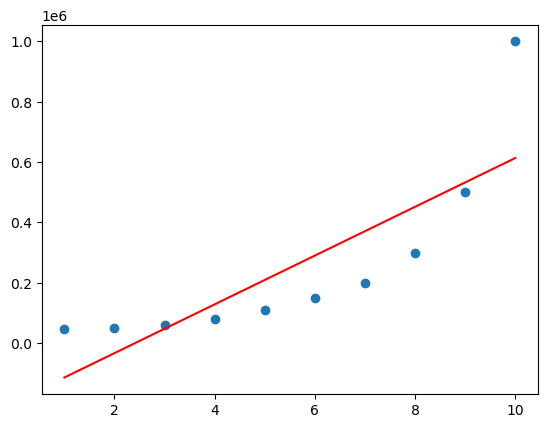

In [4]:
linear_model = LinearRegression()
linear_model.fit(X, y)
linear_model.score(X, y)

plt.scatter(X, y, label="Actual")
plt.plot(X, linear_model.predict(X), color='red');

as we can see, simple lineinear model is not good enough to fit the data. we can try polynomial models. we can try degree 2 and degree ee 4 polynomial models

In [8]:
poly = PolynomialFeatures(degree=2)
d2_df = poly.fit_transform(X)
d2_model = LinearRegression()
d2_model.fit(d2_df, y)
d2_model.score(d2_df, y)

0.9162082221443943

In [9]:
poly = PolynomialFeatures(degree=4)
d4_df = poly.fit_transform(X)
d4_model = LinearRegression()
d4_model.fit(d4_df, y)
d4_model.score(d4_df, y)

0.9973922891706613

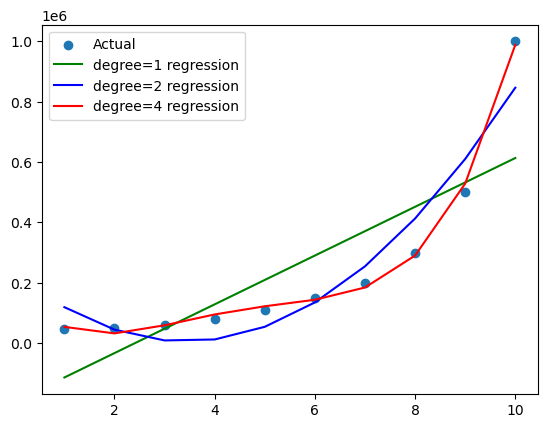

In [10]:
plt.scatter(X, y, label="Actual")
plt.plot(X, linear_model.predict(X), color='green', label='degree=1 regression')
plt.plot(X, d2_model.predict(d2_df), color='blue', label='degree=2 regression')
plt.plot(X, d4_model.predict(d4_df), color='red', label='degree=4 regression')
plt.legend();

As we can see, the 2 degree model yields a pretty respectable result (91%) and 4 degree is almost perfect sitting at 99.7% accuracy. we call this overfitting. this happens when the model is hugging the train data ( the red line), resulting in really bad results when given new data. by using a more moderate degree such as 2, we can see even tho it may not be as perfect on the train data, it will perform marginally better on new unseen data ( blue line).